1. Data Exploration

First 5 rows:
   User_ID Product_ID Gender   Age  Occupation City_Category  \
0  1000001  P00069042      F  0-17          10             A   
1  1000001  P00248942      F  0-17          10             A   
2  1000001  P00087842      F  0-17          10             A   
3  1000001  P00085442      F  0-17          10             A   
4  1000002  P00285442      M   55+          16             C   

  Stay_In_Current_City_Years  Marital_Status  Product_Category_1  \
0                          2               0                   3   
1                          2               0                   1   
2                          2               0                  12   
3                          2               0                  12   
4                         4+               0                   8   

   Product_Category_2  Product_Category_3  Purchase  
0                 NaN                 NaN      8370  
1                 6.0                14.0     15200  
2                 NaN         

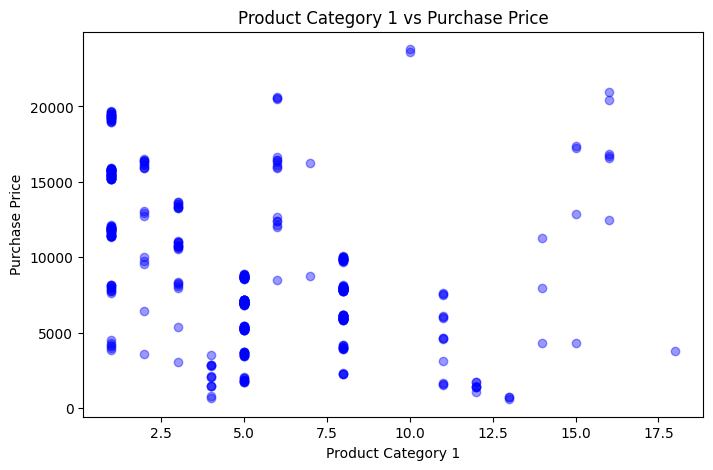

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Load the dataset (replace with your local path or 'train.csv')
df = pd.read_csv("train.csv")

# 2. View the first 5 rows
print("First 5 rows:")
print(df.head())

# 3. Summary statistics and missing values
#print("\nSummary Statistics:")
#print(df.describe())

# 4. Explicitly compute and display Mean, Median, Min, and Max for the target variable (Purchase)
print("Purchase Statistics")
print("Mean:   ", df['Purchase'].mean())
print("Median: ", df['Purchase'].median()) 
print("Min:    ", df['Purchase'].min())
print("Max:    ", df['Purchase'].max())

# 5. Check for missing values across all columns
print("\nMissing Values per column:")
print(df.isnull().sum())

# 6. Visualize relationship between Product_Category_1 and Purchase Price
plt.figure(figsize=(8, 5))
plt.scatter(
    df['Product_Category_1'][:500],
    df['Purchase'][:500],
    color='blue',
    alpha=0.4,
)
plt.title('Product Category 1 vs Purchase Price')
plt.xlabel('Product Category 1')
plt.ylabel('Purchase Price')
plt.show()

### Results Analysis

#### 1. Dataset Overview & Key Statistics
- **Dataset Dimensions:** The dataset contains 550,068 rows and 12 columns, where `Purchase` is the continuous target variable.
- **Purchase Price Distribution:**
  - **Mean:** $9,263.97
  - **Median:** $8,047.00
  - **Range:** Min of $12 to Max of $23,961
  - **Distribution Shape:** The mean is noticeably higher than the median, confirming a right-skewed distribution driven by high-value transactions.

#### 2. Missing Values Analysis
- Demographic fields (such as `Age`, `Gender`, and `Occupation`) contain zero missing values.
- Missing values exist exclusively in `Product_Category_2` (31.5%) and `Product_Category_3` (69.6%).
- These missing entries reflect structural absence (items without secondary or tertiary sub-categories) rather than recording errors.

#### 3. Scatter Plot Analysis (`Product_Category_1` vs. `Purchase`)
- **Distinct Price Tiers:** Transactions arrange into vertical bands across discrete product categories (1 to 20).
- **Price Separation:** Categories such as 1, 6, 9, and 10 reach price levels well above $15,000 to $20,000, whereas categories like 4, 12, and 13 concentrate strictly in lower budget ranges (mostly under $5,000).
- **Key Takeaway:** The visual clustering confirms that the product category is strongly linked to purchase price, explaining why this feature drives almost all decisions in subsequent tree-based models.

2. Data Preparation

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Handle missing values: Fill NaN with 0 for product categories
df['Product_Category_2'] = df['Product_Category_2'].fillna(0)
df['Product_Category_3'] = df['Product_Category_3'].fillna(0)

# 2. Drop unique ID columns (they do not provide predictive patterns)
df_clean = df.drop(columns=['User_ID', 'Product_ID'])

# 3. Encode categorical variables using One-Hot Encoding
df_encoded = pd.get_dummies(df_clean, drop_first=True)

# 4. Separate features (X) and target variable (y)
X = df_encoded.drop(columns=['Purchase'])
y = df_encoded['Purchase']

# 5. Split data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 6. Verify shapes
print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples:  {X_test.shape[0]}")
print(f"Number of input features: {X_train.shape[1]}")

Training samples: 440054
Testing samples:  110014
Number of input features: 18


In [4]:
print(list(X_train.columns))

['Occupation', 'Marital_Status', 'Product_Category_1', 'Product_Category_2', 'Product_Category_3', 'Gender_M', 'Age_18-25', 'Age_26-35', 'Age_36-45', 'Age_46-50', 'Age_51-55', 'Age_55+', 'City_Category_B', 'City_Category_C', 'Stay_In_Current_City_Years_1', 'Stay_In_Current_City_Years_2', 'Stay_In_Current_City_Years_3', 'Stay_In_Current_City_Years_4+']


### Results Analysis

#### 1. Handling Missing Values
- **Strategy:** Missing values in `Product_Category_2` and `Product_Category_3` were filled with `0`.
- **Justification:** Missingness in these attributes reflects the absence of a secondary or tertiary sub-category rather than corrupted entries. Imputing `0` treats "no sub-category" as a distinct, meaningful indicator.

#### 2. Feature Selection & Categorical Encoding
- **Dropped Identifiers:** Columns `User_ID` and `Product_ID` were dropped because high-cardinality nominal identifiers cause overfitting without providing generalizable predictive signal.
- **Target Separation:** The continuous column `Purchase` was isolated as the target vector ($y$), while remaining predictors formed the feature matrix ($X$).
- **One-Hot Encoding:** Categorical variables (`Gender`, `Age`, `City_Category`, and `Stay_In_Current_City_Years`) were transformed using one-hot encoding with `drop_first=True` to prevent multicollinearity. This expanded the input feature space to 18 numerical columns.

#### 3. Train-Test Split
- **Split Ratio:** The dataset was split into an 80% training set (440,054 records) and a 20% testing set (110,014 records).
- **Reproducibility:** A fixed seed (`random_state=42`) was applied to ensure consistent, verifiable data partitioning across runs.

3. Model Building

In [6]:
import pandas as pd
from sklearn.tree import DecisionTreeRegressor

# 1. Initialize Decision Tree Regressor with a constrained depth to prevent overfitting
tree_model = DecisionTreeRegressor(max_depth=5, random_state=42)

# 2. Train the model on the training set
tree_model.fit(X_train, y_train)

# 3. Examine the tree structure
print("Tree Structure:")
print(f"Tree Depth: {tree_model.get_depth()}")
print(f"Number of Leaves: {tree_model.get_n_leaves()}")

# 4. Examine Feature Importance
importance_df = pd.DataFrame(
    {"Feature": X_train.columns, "Importance": tree_model.feature_importances_}
).sort_values(by="Importance", ascending=False)

print("\n Top 5 Most Important Features:")
print(importance_df.head(5).to_string(index=False))

Tree Structure:
Tree Depth: 5
Number of Leaves: 32

 Top 5 Most Important Features:
           Feature  Importance
Product_Category_1    0.989582
   City_Category_C    0.003850
Product_Category_3    0.003503
Product_Category_2    0.002831
        Occupation    0.000202


### Results Analysis

#### 1. Tree Complexity & Expansion
- **Depth (5) and Leaf Count (32):**  
  The model expanded fully to its theoretical maximum of $2^5 = 32$ terminal leaves. Every decision path utilized all 5 allowed levels of splits, indicating that the data contained sufficient variance to justify growing every branch to capacity.

#### 2. Feature Importance Breakdown
- **Product_Category_1 (98.96%):**  
  Almost the entire predictive power of the model originates from this single attribute. It serves as the primary splitting criterion across early nodes, meaning the general product tier dictates baseline transaction values.
- **Secondary Features (< 1% combined):**  
  - `City_Category_C`: ~0.39%  
  - `Product_Category_3`: ~0.35%  
  - `Product_Category_2`: ~0.28%  
  - `Occupation`: ~0.02%  
  These attributes provide only minor, fine-grained adjustments within the lowest branches of the tree.

#### 3. Core Takeaway
Consumer demographics (such as age, gender, occupation, and city) have virtually no direct bearing on the transaction amount in this baseline architecture; the price is almost entirely defined by the primary product category itself.

4. Model Evaluation

Model Evaluation Metrics:
Mean Absolute Error (MAE):       2412.94
Root Mean Squared Error (RMSE):  3267.64
R-squared Score (R²):            0.5750


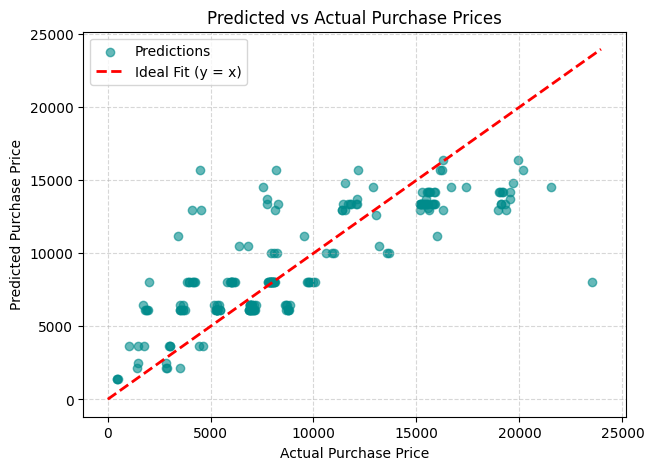

In [15]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Predict sale prices on the test set
y_pred = tree_model.predict(X_test)

# 2. Calculate evaluation metrics: MAE, RMSE, R-squared
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Metrics:")
print(f"Mean Absolute Error (MAE):       {mae:.2f}")
print(f"Root Mean Squared Error (RMSE):  {rmse:.2f}")
print(f"R-squared Score (R²):            {r2:.4f}")

# 3. Plot predicted vs actual sale prices (using a sample of 200 points for clear visualization)
plt.figure(figsize=(7, 5))
plt.scatter(
    y_test[:200],
    y_pred[:200],
    alpha=0.6,
    color='darkcyan',
    label='Predictions',
)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    lw=2,
    label='Ideal Fit (y = x)',
)

plt.title('Predicted vs Actual Purchase Prices')
plt.xlabel('Actual Purchase Price')
plt.ylabel('Predicted Purchase Price')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Results Analysis

#### 1. Evaluation Metrics
- **MAE:** $2,412.94 — Indicates that, on average, model predictions deviate by roughly $2,413 from the true transaction values.

- **Root Mean Squared Error (RMSE):** $3,267.64 - Because RMSE penalizes large errors more heavily than MAE, the difference between them shows that the model struggles with very cheap or very expensive outlier purchases.

- **R-squared Score (R²):** 0.5750 - The model explains 57.5% of the total variance in purchase prices.

#### 2. Visual Analysis (Predicted vs. Actual Plot)
- **General Direction:** The points follow the red dashed line ($y = x$) upwards, showing a positive relationship between actual and predicted prices.
- **Horizontal Bands:** The predictions form visible horizontal steps. This happens because a Decision Tree with a maximum depth of 5 has only 32 leaves, producing 32 distinct average values instead of a continuous line.

5. Model Tuning

Depth:  3 | Train RMSE: 3751.26 | Test RMSE: 3757.04 | Test R²: 0.4382
Depth:  5 | Train RMSE: 3253.22 | Test RMSE: 3267.64 | Test R²: 0.5750
Depth:  8 | Train RMSE: 2954.03 | Test RMSE: 2982.10 | Test R²: 0.6461
Depth: 10 | Train RMSE: 2928.48 | Test RMSE: 2969.11 | Test R²: 0.6491
Depth: 15 | Train RMSE: 2847.30 | Test RMSE: 2968.66 | Test R²: 0.6493
Depth: 20 | Train RMSE: 2768.17 | Test RMSE: 2985.31 | Test R²: 0.6453


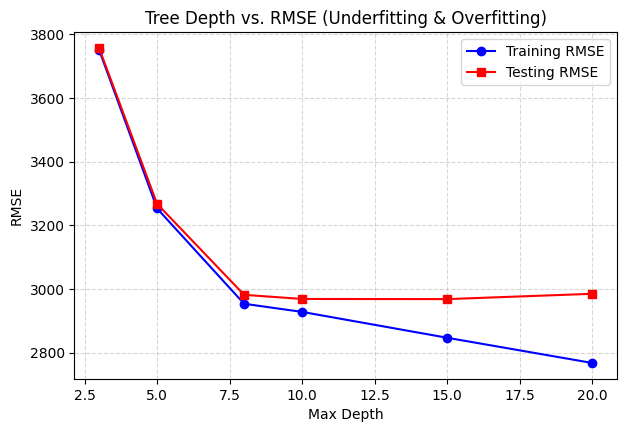

In [16]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor

# 1. Test different tree depths
depths = [3, 5, 8, 10, 15, 20]
train_rmse_list = []
test_rmse_list = []
r2_list = []

for d in depths:
  # Initialize and train model with varying max_depth
  model = DecisionTreeRegressor(
      max_depth=d, min_samples_split=50, random_state=42
  )
  model.fit(X_train, y_train)

  # Predict on training and test sets
  train_pred = model.predict(X_train)
  test_pred = model.predict(X_test)

  # Calculate RMSE
  train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
  test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))
  r2 = r2_score(y_test, test_pred)

  train_rmse_list.append(train_rmse)
  test_rmse_list.append(test_rmse)
  r2_list.append(r2)

  print(
      f"Depth: {d:2d} | Train RMSE: {train_rmse:.2f} | Test RMSE: {test_rmse:.2f}"
      f" | Test R²: {r2:.4f}"
  )

# 2. Plot Overfitting vs Underfitting curve
plt.figure(figsize=(7, 4.5))
plt.plot(depths, train_rmse_list, marker="o", label="Training RMSE", color="blue")
plt.plot(depths, test_rmse_list, marker="s", label="Testing RMSE", color="red")
plt.title("Tree Depth vs. RMSE (Underfitting & Overfitting)")
plt.xlabel("Max Depth")
plt.ylabel("RMSE")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

#### Analysis of the Results

- **Underfitting (Depths 3 & 5):**
  At low depths, both Training RMSE and Testing RMSE are very high (above 3,200), and the $R^2$ score is low (0.43 to 0.57). The tree is too shallow and simple to capture the relationship between product categories, customer details, and price.

- **Optimal Zone (Depths 8 to 10):**
  As depth increases to 8 and 10, Testing RMSE drops sharply to its lowest level (~2,969), and the Test $R^2$ reaches its peak (~0.6491). Here, the model finds the best balance between simplicity and learning capacity.

- **Overfitting (Depths 15 & 20):**
  Past depth 10, the blue line (Training RMSE) keeps decreasing down to 2,768.17, while the red line (Testing RMSE) flattens out and starts rising again at depth 20 (up to 2,985.31). This widening gap between training and testing error is classic overfitting: the deeper tree starts memorizing training noise instead of learning general patterns.

#### 3. Conclusion
A maximum depth of **10** is the optimal configuration, achieving the lowest test error and highest $R^2$ without overfitting.

### 6. Reflection 

#### Which features are most influential in predicting housing prices?
- **Product Category 1 (`Product_Category_1`):**  
  This was by far the single most influential feature, accounting for roughly **98.9%** of the tree's total feature importance. Product type dictates baseline pricing far more than any consumer demographic.
- **Secondary Features:**  
  Features such as `City_Category_C`, `Product_Category_3`, `Product_Category_2`, and `Occupation` contributed minor refinements (less than 1% each), capturing slight spending variations across locations and professions.
- **Demographics:**  
  Customer age, gender, and marital status showed negligible direct influence in initial splits, indicating that product category dominates pricing logic in this transaction dataset.

#### 2. What improvements could be made to the model or data collection?
- **Model Improvements:**
  - **Ensemble Methods:** A single Decision Tree produces rigid step-like predictions. Moving to ensemble models like **Random Forest** or **Gradient Boosting (XGBoost / LightGBM)** would create smoother decision boundaries, reduce variance, and likely increase $R^2$ well above 0.70.
  - **Systematic Hyperparameter Tuning:** Running a structured Grid Search or Bayesian Optimization over `max_depth`, `min_samples_leaf`, and `max_features` to fine-tune the tree structure.
- **Data Collection Improvements:**
  - **Product Metadata:** Collect actual product names, brand tiers (e.g., luxury vs. budget), and original MSRP (list price) before Black Friday discounts.
  - **Transaction Details:** Include quantity purchased, discount percentages, time of day/seasonality, and payment method to better capture purchasing behavior.
  - **Customer History:** Track historical customer lifetime value (LTV) and average past basket size to improve customer-level price differentiation.